# PACV — Autenticação de copresença acústica

Este notebook corresponde aos experimentos do **Capítulo 5 — Autenticação de Copresença Acústica em Sistemas Ciberfísicos** da tese *Explorando Propriedades Acústicas na Proteção de Dispositivos Ciberfísicos*.

O método passivo compara representações acústicas capturadas pelo **Prover** e pelo **Verifier**. O estudo veicular distingue pares genuínos da mesma sessão (**GP-SS**), pares falsos de sessões distintas do mesmo veículo (**FP-SV**) e pares falsos de veículos diferentes (**FP-DV**).

O notebook reproduz o procedimento computacional disponível: indexação, pareamento, alinhamento, descritores, cinco verificadores consolidados, curvas ROC e precisão–revocação e comparação com os valores publicados. **O código original não separa sessões de treinamento e teste.** As métricas calculadas caracterizam esse procedimento; a validação independente por sessões descrita na tese depende do manifesto de partições original. As diferenças metodológicas estão detalhadas nas seções correspondentes deste notebook.

## 1. Ambiente e configuração

Instale `requirements.txt` em um ambiente Python 3.9 e execute **Restart Kernel and Run All Cells**. Preserve a organização das 112 gravações em `data/raw/`, com as pastas dos veículos, capturas e dispositivos (`Celular Preto` para Prover; `Celular Rosa` para Verifier). Os JSON de telemetria não são utilizados nem exportados.

Os sinais são convertidos para mono a 16 kHz, filtrados entre 150 e 7.600 Hz e normalizados pelo percentil 95 da amplitude absoluta, com recorte nos limites correspondentes. O alinhamento global busca atrasos em ±5 s. As janelas têm 10 s, sem sobreposição. O refinamento local busca ±0,25 s.

A execução integral envolve 1.356 pares de gravações. Os descritores são armazenados em cache por par, com assinatura do código, dos parâmetros, das versões e dos arquivos de áudio. Os classificadores e seus escores são recalculados. As saídas locais ficam em `results/`.

In [1]:
from __future__ import annotations
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS", "NUMBA_NUM_THREADS"):
    os.environ[variable] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_DETERMINISTIC_OPS"] = "1"
from pathlib import Path
from typing import List, Dict, Optional, Tuple
from itertools import combinations
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache
from importlib.metadata import version
import hashlib, inspect, json, random, re
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from scipy import signal
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import EmpiricalCovariance
from sklearn.metrics import roc_curve, auc, average_precision_score, precision_recall_curve, confusion_matrix, accuracy_score, precision_recall_fscore_support, roc_auc_score
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from threadpoolctl import threadpool_limits
threadpool_limits(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.threading.set_intra_op_parallelism_threads(1)
VERSIONS = {name:version(name) for name in ["numpy","pandas","scipy","librosa","scikit-learn","tensorflow","soundfile","matplotlib"]}
plt.rcParams.update({"figure.figsize":(8,5), "axes.spines.top":False, "axes.spines.right":False})
pd.set_option("display.precision",6)
display(pd.Series(VERSIONS,name="Versão").to_frame())

,Versão
numpy,1.24.3
pandas,2.3.3
scipy,1.13.1
librosa,0.10.1
scikit-learn,1.6.1
tensorflow,2.13.1
soundfile,0.13.1
matplotlib,3.9.4


In [2]:
DATASET_ROOT = Path("data/raw")
EXPERIMENT_ID = "Experimento6"
SR_TARGET = 16000
HPF_CUT, LPF_CUT = 150.0, 7600.0
WIN_SEC, HOP_SEC = 10.0, 10.0
XCORR_MAX_LAG_S, MICRO_LAG_S = 5.0, 0.25
N_MFCC = 20
RANDOM_STATE = 42
N_JOBS = 4
LIBROSA_OK = True
USE_FEATURE_CACHE = True
RESULTS = Path("results")
FEATURE_CACHE = Path("data/derived/pairs")
AUDIO_CACHE = Path(".cache/audio")
for folder in [RESULTS/"figures",FEATURE_CACHE,AUDIO_CACHE]:folder.mkdir(parents=True,exist_ok=True)
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()
assert DATASET_ROOT.is_dir(), "Disponibilize os WAV em data/raw/, conforme o README."

def save_figure(stem):
    figure=plt.gcf()
    figure.savefig(RESULTS/"figures"/f"{stem}.png",dpi=180,bbox_inches="tight")
    figure.savefig(RESULTS/"figures"/f"{stem}.pdf",bbox_inches="tight")
    plt.show()
    plt.close(figure)

## 2. Inventário e grupos de sessão

A chave `session_group = vehicle | capture | exp` associa as gravações à sua sessão. Os metadados organizam os pares e não entram nos vetores acústicos. Caminhos exportados são relativos ao diretório dos dados.

In [3]:
# Identificação das gravações
import re

AUDIO_EXTS = {".wav"}
_ts_pat = re.compile(r"(\d{4}-\d{2}-\d{2})[_-](\d{2}-\d{2}-\d{2})")


def list_audio_files(root: Path) -> List[Path]:
    files = [p for p in root.rglob("*") if p.suffix.lower() in AUDIO_EXTS]
    print(f"Arquivos WAV encontrados: {len(files)}")
    return files


def norm(s: str) -> str:
    return s.lower().strip()


def detect_vehicle(parts: List[str]) -> str:
    s = norm("/".join(parts))
    if "civic" in s:
        return "Honda Civic"
    if "city" in s:
        return "Honda City"
    return "Unknown"


def detect_role(path: Path) -> str:
    s = norm(path.as_posix())
    if "preto" in s:
        return "PROVER"
    if "rosa" in s:
        return "VERIFIER"
    return "UNKNOWN"


def extract_timestamp_from_name(name: str) -> Optional[pd.Timestamp]:
    """Extrai o horário nominal do nome do arquivo."""
    m = _ts_pat.search(name)
    if not m:
        return None
    day, hms = m.groups()
    hms = hms.replace("-", ":")
    try:
        return pd.to_datetime(f"{day} {hms}")
    except Exception:
        return None


def extract_metadata(p: Path) -> Dict:
    parts = list(p.relative_to(DATASET_ROOT).parts)
    vehicle = detect_vehicle(parts)
    role = detect_role(p)
    capture = next((x for x in parts if "captur" in norm(x)), "UnknownCap")
    exp = EXPERIMENT_ID
    segment = p.stem
    json_p = None
    t_start = extract_timestamp_from_name(p.stem) or extract_timestamp_from_name(p.name)
    return dict(
        vehicle=vehicle,
        capture=capture,
        exp=exp,
        segment=segment,
        role=role,
        audio_path=p,
        json_path=json_p,
        t_start=t_start,
    )


def build_index(root: Path) -> pd.DataFrame:
    files = list_audio_files(root)
    rows = [extract_metadata(p) for p in files]
    df = pd.DataFrame(rows)
    if df.empty:
        raise RuntimeError("Nenhum WAV encontrado em data/raw.")
    df["session_key"] = df["vehicle"] + " | " + df["capture"] + " | " + df["exp"]
    df = df.sort_values(["vehicle", "capture", "exp", "role", "segment"]).reset_index(drop=True)
    return df


def _parse_seg_time(seg: str) -> Optional[pd.Timestamp]:
    """Interpreta o horário com milissegundos."""
    if not isinstance(seg, str):
        return pd.NaT
    s = seg.lower()
    m = re.search(r"(\d{4})[-_](\d{2})[-_](\d{2})[_-](\d{2})[-_](\d{2})[-_](\d{2})(?:[_-](\d{1,3}))?", s)
    if not m:
        return pd.NaT
    Y, M, D, h, m2, s2, ms = m.groups()
    frac = int(ms) / 1000.0 if ms else 0.0
    try:
        return pd.Timestamp(int(Y), int(M), int(D), int(h), int(m2), int(s2)) + pd.to_timedelta(frac, unit="s")
    except Exception:
        return pd.NaT


def _ensure_pairing_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    if "session_group" not in df.columns:
        df["session_group"] = (
            df["vehicle"].astype(str) + " | " +
            df["capture"].astype(str) + " | " +
            df["exp"].astype(str)
        )
    if "seg_time" not in df.columns:
        df["seg_time"] = df["segment"].astype(str).apply(_parse_seg_time)
    return df

In [4]:
idx_df = _ensure_pairing_columns(build_index(DATASET_ROOT))
assert not idx_df.audio_path.duplicated().any()
assert not idx_df.role.eq("UNKNOWN").any()
assert set(idx_df.vehicle) <= {"Honda City", "Honda Civic"}, "Veículo não identificado."
assert not idx_df.capture.eq("UnknownCap").any(), "Captura não identificada."
assert idx_df.seg_time.notna().all(), "Horário ausente no nome de algum WAV."

def inspect_audio(path):
    raw=path.read_bytes()
    info=sf.info(path)
    return {"arquivo":path.relative_to(DATASET_ROOT).as_posix(),"sha256":hashlib.sha256(raw).hexdigest(),
            "amostras":info.frames,"taxa":info.samplerate,"canais":info.channels,"duracao_s":info.duration}
with ThreadPoolExecutor(max_workers=N_JOBS) as executor:
    audio_inventory=pd.DataFrame(executor.map(inspect_audio,idx_df.audio_path))
audio_inventory.to_csv(RESULTS/"inventario_audio.csv",index=False)
AUDIO_HASHES=dict(zip(audio_inventory.arquivo,audio_inventory.sha256))
dataset_digest=hashlib.sha256(audio_inventory.to_csv(index=False).encode()).hexdigest()
index_export=idx_df.drop(columns=["json_path"]).copy()
index_export["audio_path"]=index_export.audio_path.map(lambda p:p.relative_to(DATASET_ROOT).as_posix())
index_export.to_csv(RESULTS/"indice_gravacoes.csv",index=False)
display(idx_df.groupby(["vehicle","capture","role"]).size().rename("Gravações").to_frame())
print("Gravações:",len(idx_df),"| Grupos de sessão:",idx_df.session_group.nunique())

Arquivos WAV encontrados: 112


Gravações
vehicle     capture   role               
Honda City  Captura01 PROVER            5
                      VERIFIER          5
            Captura02 PROVER            8
                      VERIFIER          8
            Captura03 PROVER            7
                      VERIFIER          7
            Captura04 PROVER           15
                      VERIFIER         15
Honda Civic Capture01 PROVER            4
                      VERIFIER          4
            Capture02 PROVER            6
                      VERIFIER          6
            Capture03 PROVER           11
                      VERIFIER         11

Gravações: 112 | Grupos de sessão: 7


## 3. Pares GP-SS, FP-SV e FP-DV

O pareamento original associa cada gravação Prover à gravação Verifier ainda disponível com horário nominal mais próximo dentro da sessão. Os negativos combinam sessões ou veículos distintos, com limite de 20.000 pares por combinação e semente 42.

Essa regra não impõe uma tolerância máxima entre horários nem documenta compensação dos relógios. A diferença nominal de início é auditada abaixo; a cotemporalidade estrita não pode ser inferida apenas do pertencimento à mesma sessão.

In [5]:
def _pair_within_group(g: pd.DataFrame) -> List[Dict]:
    """Associa gravações Prover e Verifier dentro da sessão."""
    rows = []
    A = g[g["role"] == "PROVER"].copy()
    B = g[g["role"] == "VERIFIER"].copy()
    if A.empty or B.empty:
        return rows

    if A["seg_time"].notna().any():
        A = A.sort_values(["seg_time", "audio_path"])
    else:
        A = A.sort_values("audio_path")
    if B["seg_time"].notna().any():
        B = B.sort_values(["seg_time", "audio_path"])
    else:
        B = B.sort_values("audio_path")

    used_B = set()
    for _, ra in A.iterrows():
        if pd.notna(ra["seg_time"]) and B["seg_time"].notna().any():
            diffs = (B["seg_time"] - ra["seg_time"]).abs()
            diffs = diffs.mask(B.index.to_series().isin(used_B), pd.to_timedelta(10**9, unit="s"))
            diff_ms = diffs.dt.total_seconds() * 1000.0
            ib = diff_ms.idxmin()
        else:
            free = [ib for ib in B.index if ib not in used_B]
            if not free:
                break
            ib = free[0]

        if ib in used_B:
            continue
        rb = B.loc[ib]
        used_B.add(ib)
        rows.append({
            "scenario": "GP-SS",
            "y": 1,
            "vehicle_pair": f"{ra['vehicle']}|{ra['vehicle']}",
            "session_A": ra["session_key"],
            "session_B": rb["session_key"],
            "audio_A": Path(ra["audio_path"]),
            "audio_B": Path(rb["audio_path"]),
            "json_A": ra["json_path"],
            "json_B": rb["json_path"],
            "session_group": ra["session_group"],
            "delta_ms": (((rb["seg_time"] - ra["seg_time"]).total_seconds() * 1000.0)
                         if (pd.notna(ra["seg_time"]) and pd.notna(rb["seg_time"])) else np.nan),
        })
    return rows


def build_pos_neg_pairs(
    df: pd.DataFrame,
    max_neg_pairs_per_combo_sv: Optional[int] = 20000,
    max_neg_pairs_per_combo_dv: Optional[int] = 20000,
    random_state: int = 42,
) -> List[Dict]:
    """Forma os três cenários de pareamento."""
    rng = np.random.default_rng(random_state)
    df = _ensure_pairing_columns(df)

    sessions = []
    for _, g in df.groupby("session_group"):
        sessions.extend(_pair_within_group(g))
    print(f"Pares de gravações GP-SS: {len(sessions)}")
    pos_df = pd.DataFrame(sessions)
    pairs = sessions[:]

    if pos_df.empty:
        print("Nenhum par GP-SS encontrado.")
        return pairs

    pos_by_vehicle = {
        veh: pos_df[pos_df["vehicle_pair"] == f"{veh}|{veh}"].copy()
        for veh in df["vehicle"].dropna().astype(str).unique()
    }
    pos_by_vehicle_group: Dict[Tuple[str, str], pd.DataFrame] = {}
    for (veh_name, sg_name), _ in df.groupby(["vehicle", "session_group"]):
        cand = pos_df[pos_df["session_group"] == sg_name]
        if not cand.empty:
            pos_by_vehicle_group[(veh_name, sg_name)] = cand.copy()

    seen_neg = set()

    print("Pares FP-SV:")
    for veh, groups in df.groupby("vehicle")["session_group"].unique().items():
        groups = sorted([g for g in groups if (veh, g) in pos_by_vehicle_group])
        if len(groups) < 2:
            continue
        for g1, g2 in combinations(groups, 2):
            P1 = pos_by_vehicle_group[(veh, g1)]
            P2 = pos_by_vehicle_group[(veh, g2)]
            cands = P1[["session_A", "audio_A", "json_A"]].reset_index(drop=True)
            cands = cands.assign(key=1).merge(
                P2[["session_B", "audio_B", "json_B"]].reset_index(drop=True).assign(key=1),
                on="key", how="inner"
            ).drop(columns="key")
            pot = len(cands)
            if pot == 0:
                continue
            if (max_neg_pairs_per_combo_sv is not None) and (pot > max_neg_pairs_per_combo_sv):
                take_idx = rng.choice(pot, size=max_neg_pairs_per_combo_sv, replace=False)
                cands = cands.iloc[take_idx]
            used = 0
            for _, r in cands.iterrows():
                key = (str(r["audio_A"]), str(r["audio_B"]))
                if key in seen_neg:
                    continue
                seen_neg.add(key)
                pairs.append({
                    "scenario": "FP-SV",
                    "y": 0,
                    "vehicle_pair": f"{veh}|{veh}",
                    "session_A": r["session_A"],
                    "session_B": r["session_B"],
                    "audio_A": r["audio_A"],
                    "audio_B": r["audio_B"],
                    "json_A": r["json_A"],
                    "json_B": r["json_B"],
                })
                used += 1
            print(f"  {veh}: {g1} x {g2} -> possíveis={pot}, utilizados={used}")

    print("Pares FP-DV:")
    vehicles = sorted([v for v, dfv in pos_by_vehicle.items() if not dfv.empty])
    for v1, v2 in combinations(vehicles, 2):
        P1 = pos_by_vehicle[v1]
        P2 = pos_by_vehicle[v2]
        if P1.empty or P2.empty:
            continue
        cands = P1[["session_A", "audio_A", "json_A"]].reset_index(drop=True)
        cands = cands.assign(key=1).merge(
            P2[["session_B", "audio_B", "json_B"]].reset_index(drop=True).assign(key=1),
            on="key", how="inner"
        ).drop(columns="key")
        pot = len(cands)
        if pot == 0:
            continue
        if (max_neg_pairs_per_combo_dv is not None) and (pot > max_neg_pairs_per_combo_dv):
            take_idx = rng.choice(pot, size=max_neg_pairs_per_combo_dv, replace=False)
            cands = cands.iloc[take_idx]
        used = 0
        for _, r in cands.iterrows():
            key = (str(r["audio_A"]), str(r["audio_B"]))
            if key in seen_neg:
                continue
            seen_neg.add(key)
            pairs.append({
                "scenario": "FP-DV",
                "y": 0,
                "vehicle_pair": f"{v1}|{v2}",
                "session_A": r["session_A"],
                "session_B": r["session_B"],
                "audio_A": r["audio_A"],
                "audio_B": r["audio_B"],
                "json_A": r["json_A"],
                "json_B": r["json_B"],
            })
            used += 1
        print(f"  {v1} x {v2} -> possíveis={pot}, utilizados={used}")

    counts = pd.Series([p["scenario"] for p in pairs]).value_counts().to_dict()
    print("Contagens por cenário:", counts)
    return pairs


def build_pairs(df: pd.DataFrame) -> List[Dict]:
    return build_pos_neg_pairs(
        df,
        max_neg_pairs_per_combo_sv=20000,
        max_neg_pairs_per_combo_dv=20000,
        random_state=42,
    )

In [6]:
pairs=build_pairs(idx_df)
assert pairs
pair_inventory=pd.DataFrame([{k:v for k,v in pair.items() if not k.startswith("json_")} for pair in pairs])
for column in ["audio_A","audio_B"]:
    pair_inventory[column]=pair_inventory[column].map(lambda p:Path(p).relative_to(DATASET_ROOT).as_posix())
pair_inventory.to_csv(RESULTS/"pares_gravacoes.csv",index=False)
assert pair_inventory.loc[pair_inventory.y.eq(1),"session_A"].equals(pair_inventory.loc[pair_inventory.y.eq(1),"session_B"])
assert (pair_inventory.loc[pair_inventory.y.eq(0),"session_A"] != pair_inventory.loc[pair_inventory.y.eq(0),"session_B"]).all()
display(pair_inventory.groupby("scenario").size().rename("Pares de gravações").to_frame())
display(pair_inventory.loc[pair_inventory.y.eq(1)].groupby("session_A").delta_ms.agg(["min","median","max"]))

Pares de gravações GP-SS: 56
Pares FP-SV:
  Honda City: Honda City | Captura01 | Experimento6 x Honda City | Captura02 | Experimento6 -> possíveis=40, utilizados=40
  Honda City: Honda City | Captura01 | Experimento6 x Honda City | Captura03 | Experimento6 -> possíveis=35, utilizados=35
  Honda City: Honda City | Captura01 | Experimento6 x Honda City | Captura04 | Experimento6 -> possíveis=75, utilizados=75
  Honda City: Honda City | Captura02 | Experimento6 x Honda City | Captura03 | Experimento6 -> possíveis=56, utilizados=56
  Honda City: Honda City | Captura02 | Experimento6 x Honda City | Captura04 | Experimento6 -> possíveis=120, utilizados=120
  Honda City: Honda City | Captura03 | Experimento6 x Honda City | Captura04 | Experimento6 -> possíveis=105, utilizados=105
  Honda Civic: Honda Civic | Capture01 | Experimento6 x Honda Civic | Capture02 | Experimento6 -> possíveis=24, utilizados=24
  Honda Civic: Honda Civic | Capture01 | Experimento6 x Honda Civic | Capture03 | Experime

,Pares de gravações
scenario,
FP-DV,735
FP-SV,565
GP-SS,56


,min,median,max
session_A,,,
Honda City | Captura01 | Experimento6,86635.0,88502.0,89492.0
Honda City | Captura02 | Experimento6,90143.0,92212.5,92892.0
Honda City | Captura03 | Experimento6,4077.0,4215.0,5514.0
Honda City | Captura04 | Experimento6,2940.0,4006.0,5540.0
Honda Civic | Capture01 | Experimento6,2204.0,2454.0,2555.0
Honda Civic | Capture02 | Experimento6,52448.0,54394.0,54964.0
Honda Civic | Capture03 | Experimento6,53193.0,54009.0,55163.0


## 4. Alinhamento e descritores acústicos

Cada janela produz 20 MFCCs, suas derivadas de primeira e segunda ordem, resumidos por média e desvio padrão populacional: 120 valores. A média e o desvio padrão do centroide, da largura de banda espectral e da taxa de cruzamento por zero acrescentam seis valores, totalizando **126 dimensões**. Usam-se FFT de 1.024 pontos e passo de 256 amostras.

Para reproduzir o código disponível, o refinamento local é aplicado somente aos pares rotulados como impostores. Essa escolha depende do rótulo real e difere de um procedimento operacional comum aos dois tipos de par. Ela é preservada nesta reprodução histórica e registrada na validação.

In [7]:
def butter_bandpass(low, high, fs, order=4):
    """Projeta o filtro passa-faixa Butterworth."""
    nyq = 0.5 * fs
    eps = 1e-3

    low = float(low)
    high = float(high)
    low = max(eps, min(low, nyq * (1 - 2 * eps)))
    high = max(low + eps, min(high, nyq * (1 - 2 * eps)))

    wn = [low / nyq, high / nyq]
    b, a = signal.butter(order, wn, btype="band")
    return b, a


def preprocess_audio(path: Path, sr: int) -> np.ndarray:
    """Converte, filtra e normaliza uma gravação."""
    y, in_sr = sf.read(path.as_posix())
    if y.ndim > 1:
        y = np.mean(y, axis=1)

    if in_sr != sr:
        y = librosa.resample(y, orig_sr=in_sr, target_sr=sr)

    b, a = butter_bandpass(HPF_CUT, LPF_CUT, fs=sr, order=4)
    y = signal.lfilter(b, a, y)

    p95 = np.percentile(np.abs(y), 95) + 1e-9
    y = np.clip(y, -p95, p95) / p95
    return y.astype(np.float32)


def segment_fixed_windows(y: np.ndarray, sr: int, win_s: float, hop_s: float) -> List[np.ndarray]:
    L = len(y)
    W = int(win_s * sr)
    H = int(hop_s * sr)
    out = []
    for start in range(0, max(0, L - W + 1), H):
        out.append(y[start:start + W])
    return out


def estimate_global_lag(yA: np.ndarray, yB: np.ndarray, sr: int,
                        max_lag_s: float = XCORR_MAX_LAG_S) -> int:
    """Estima o atraso global por correlação cruzada."""
    max_lag = int(max_lag_s * sr)
    n = min(len(yA), len(yB))
    if n < sr:
        return 0
    a = yA[:n]
    b = yB[:n]
    corr = signal.correlate(a, b, mode="full", method="auto")
    lags = signal.correlation_lags(a.size, b.size, mode="full")
    mask = (lags >= -max_lag) & (lags <= max_lag)
    lag = int(lags[mask][np.argmax(corr[mask])])
    return lag


def apply_lag_pair(yA: np.ndarray, yB: np.ndarray, lag: int) -> Tuple[np.ndarray, np.ndarray]:
    """Aplica o atraso e preserva o trecho comum."""
    if lag > 0:
        yA2 = yA[lag:]
        yB2 = yB[:len(yA2)]
    elif lag < 0:
        lag = abs(lag)
        yB2 = yB[lag:]
        yA2 = yA[:len(yB2)]
    else:
        yA2, yB2 = yA, yB
    L = min(len(yA2), len(yB2))
    return yA2[:L], yB2[:L]


def micro_align(a: np.ndarray, b: np.ndarray, sr: int, micro_lag_s: float = MICRO_LAG_S) -> Tuple[np.ndarray, np.ndarray]:
    """Refina o alinhamento no intervalo local."""
    max_lag = int(micro_lag_s * sr)
    if max_lag <= 0 or len(a) < 2 * max_lag or len(b) < 2 * max_lag:
        return a, b
    corr = signal.correlate(a, b, mode="full", method="auto")
    lags = signal.correlation_lags(a.size, b.size, mode="full")
    mask = (lags >= -max_lag) & (lags <= max_lag)
    lag = int(lags[mask][np.argmax(corr[mask])])
    return apply_lag_pair(a, b, lag)


def feat_window(y: np.ndarray, sr: int) -> np.ndarray:
    """Extrai os 126 descritores por dispositivo e janela."""
    # Parâmetros dos quadros
    n_fft = 1024
    hop = 256
    # MFCCs e derivadas
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC, n_fft=n_fft, hop_length=hop)
    d1   = librosa.feature.delta(mfcc)
    d2   = librosa.feature.delta(mfcc, order=2)
    allm = np.vstack([mfcc, d1, d2])                       # (60, T)
    mu  = np.mean(allm, axis=1)
    sd  = np.std(allm, axis=1) + 1e-6

    # Descritores complementares
    sc  = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=n_fft, hop_length=hop)
    sbw = librosa.feature.spectral_bandwidth(y=y, sr=sr, n_fft=n_fft, hop_length=hop)
    zcr = librosa.feature.zero_crossing_rate(y, frame_length=n_fft, hop_length=hop)

    comp = np.array([np.mean(sc), np.std(sc), np.mean(sbw), np.std(sbw), np.mean(zcr), np.std(zcr)], dtype=np.float32)
    feat = np.concatenate([mu, sd, comp], axis=0)
    return feat.astype(np.float32)

In [8]:
EXTRACTION_PARAMETERS={"sr":SR_TARGET,"band":[HPF_CUT,LPF_CUT],"window":WIN_SEC,"hop":HOP_SEC,
                       "lag":XCORR_MAX_LAG_S,"micro_lag":MICRO_LAG_S,"mfcc":N_MFCC,
                       "micro_alignment":"apenas impostores; regra original"}
extractor_functions=[butter_bandpass,preprocess_audio,segment_fixed_windows,estimate_global_lag,apply_lag_pair,micro_align,feat_window]
extractor_code="\n".join(inspect.getsource(function) for function in extractor_functions)
extractor_digest=hashlib.sha256((extractor_code+json.dumps(EXTRACTION_PARAMETERS,sort_keys=True)+json.dumps(VERSIONS,sort_keys=True)).encode()).hexdigest()

@lru_cache(maxsize=112)
def load_audio(path, sr):
    relative=Path(path).relative_to(DATASET_ROOT).as_posix()
    key=hashlib.sha256((relative+AUDIO_HASHES[relative]+extractor_digest).encode()).hexdigest()
    target=AUDIO_CACHE/f"{key}.npy"
    if not target.exists():np.save(target,preprocess_audio(Path(path),sr))
    return np.load(target,mmap_mode="r")

print("Assinatura do extrator:",extractor_digest)

Assinatura do extrator: 1b96cdd3609779ac87152fd91d4827c47ce0612debbfc4f7c17036a6264df8ca


In [9]:
def features_for_pair(a_path: Path, b_path: Path, sr: int = SR_TARGET,
                      win_s: float = WIN_SEC, hop_s: float = HOP_SEC,
                      do_micro_align: bool = False) -> Tuple[np.ndarray, np.ndarray]:
    """Extrai os descritores das janelas alinhadas."""
    yA = load_audio(a_path, sr)
    yB = load_audio(b_path, sr)

    lag = estimate_global_lag(yA, yB, sr, max_lag_s=XCORR_MAX_LAG_S)
    yA2, yB2 = apply_lag_pair(yA, yB, lag)

    segA = segment_fixed_windows(yA2, sr, win_s, hop_s)
    segB = segment_fixed_windows(yB2, sr, win_s, hop_s)

    m = min(len(segA), len(segB))
    if m == 0:
        return np.zeros((0, 1), np.float32), np.zeros((0, 1), np.float32)

    FA, FB = [], []
    for i in range(m):
        a = segA[i]
        b = segB[i]
        if do_micro_align:
            a, b = micro_align(a, b, sr, micro_lag_s=MICRO_LAG_S)
        L = min(len(a), len(b))
        if L <= 100:
            continue
        FA.append(feat_window(a[:L], sr))
        FB.append(feat_window(b[:L], sr))

    if not FA:
        return np.zeros((0, 1), np.float32), np.zeros((0, 1), np.float32)

    return np.vstack(FA), np.vstack(FB)

In [10]:
def extract_pair(pair):
    a=Path(pair["audio_A"]).relative_to(DATASET_ROOT).as_posix()
    b=Path(pair["audio_B"]).relative_to(DATASET_ROOT).as_posix()
    do_micro=pair["y"] == 0
    signature={"a":a,"b":b,"hash_a":AUDIO_HASHES[a],"hash_b":AUDIO_HASHES[b],"micro":do_micro,
               "extractor":extractor_digest,"pair_code":inspect.getsource(features_for_pair)}
    key=hashlib.sha256(json.dumps(signature,sort_keys=True).encode()).hexdigest()
    target=FEATURE_CACHE/f"{key}.npz"
    if USE_FEATURE_CACHE and target.exists():
        with np.load(target,allow_pickle=False) as data:FA,FB=data["FA"],data["FB"]
    else:
        FA,FB=features_for_pair(pair["audio_A"],pair["audio_B"],do_micro_align=do_micro)
        np.savez_compressed(target,FA=FA,FB=FB)
    if len(FA) == 0:
        return []
    assert FA.shape == FB.shape
    assert FA.shape[1] == 126 and np.isfinite(FA).all() and np.isfinite(FB).all()
    return [{"scenario":pair["scenario"],"y":pair["y"],"session_A":pair["session_A"],"session_B":pair["session_B"],
             "pathA":a,"pathB":b,"win_idx":i,"FA":FA[i],"FB":FB[i]} for i in range(len(FA))]

# Inicializa o extrator antes de iniciar os pares em paralelo.
first_audio=load_audio(pairs[0]["audio_A"],SR_TARGET)
assert feat_window(first_audio[:int(WIN_SEC*SR_TARGET)],SR_TARGET).shape == (126,)
rows=[]
with ThreadPoolExecutor(max_workers=N_JOBS) as executor:
    for index, pair_rows in enumerate(executor.map(extract_pair,pairs),1):
        rows.extend(pair_rows)
        if index%50==0 or index==len(pairs):print(f"Pares processados: {index}/{len(pairs)}",flush=True)
comparisons=pd.DataFrame(rows)
FA=np.vstack(comparisons.FA)
FB=np.vstack(comparisons.FB)
y_vec=comparisons.y.to_numpy(dtype=int)
comparisons.drop(columns=["FA","FB"]).to_csv(RESULTS/"janelas_pareadas.csv",index=False)
np.savez_compressed(RESULTS/"descritores_pareados.npz",FA=FA,FB=FB)
display(comparisons.groupby("scenario").size().rename("Janelas pareadas").to_frame())
print("Total de pares de janelas:",len(comparisons))

Pares processados: 50/1356


Pares processados: 100/1356


Pares processados: 150/1356


Pares processados: 200/1356


Pares processados: 250/1356


Pares processados: 300/1356


... (20 outputs left out)

Pares processados: 1350/1356


Pares processados: 1356/1356


,Janelas pareadas
scenario,
FP-DV,19762
FP-SV,15719
GP-SS,1577


Total de pares de janelas: 37058


## 5. Representação pareada e verificadores BASE

A concatenação `[r_P, r_V, |r_P − r_V|, r_P ⊙ r_V, cosseno]` produz **505 dimensões**. No código original, a padronização dos blocos BASE é ajustada com todos os pares, inclusive impostores. As diferenças genuínas utilizadas na estimação da covariância também aparecem na avaliação.

O método `EmpiricalCovariance.mahalanobis` retorna a distância **quadrática**; o escore orientado é seu negativo. Essa convenção reproduz os limiares do notebook, embora a equação do capítulo apresente a raiz quadrada. Os verificadores BASE-cosseno e BASE-euclidiana usam os blocos Prover/Verifier padronizados separadamente.

In [11]:
def enrich(v):
    return np.asarray(v).ravel()

def build_pair_vector(a_vec, b_vec):
    A = enrich(a_vec)
    B = enrich(b_vec)
    cos = np.dot(A, B) / (np.linalg.norm(A) * np.linalg.norm(B) + 1e-12)
    return np.hstack([A, B, np.abs(A - B), A * B, cos])


X_pairs=np.vstack([build_pair_vector(a,b) for a,b in zip(FA,FB)])
assert X_pairs.shape == (len(y_vec),505)
print("Dimensão por dispositivo:",FA.shape[1],"| Dimensão pareada:",X_pairs.shape[1])

Dimensão por dispositivo: 126 | Dimensão pareada: 505


In [12]:
scaler_all = StandardScaler()
Xz = scaler_all.fit_transform(X_pairs)

n_features = FA.shape[1]
A = Xz[:, :n_features]
B = Xz[:, n_features:2 * n_features]

def cosine_sim_batch(a, b):
    num = np.sum(a * b, axis=1)
    den = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
    den = np.where(den == 0, 1e-12, den)
    return num / den

base_cos = cosine_sim_batch(A, B)
base_l2 = np.linalg.norm(A - B, axis=1)
D = Xz[:, 2 * n_features:3 * n_features]
base_cov = EmpiricalCovariance().fit(D[y_vec == 1])
base_maha = base_cov.mahalanobis(D)

extended_method_scores = {
    "BASE-cos": {"score": base_cos, "higher_is_genuine": True},
    "BASE-euclidean": {"score": base_l2, "higher_is_genuine": False},
    "BASE-mahalanobis": {"score": base_maha, "higher_is_genuine": False},
}

## 6. AE++ e fusão de escores

O AE++ disponível utiliza a topologia **505 → 252 → 126 → 126 → 126 → 252 → 505**, com ReLU nas camadas ocultas, saída linear, BatchNormalization, dropout de 0,1 e regularização L2 de 10⁻⁵. Essa topologia difere do gargalo de 63 dimensões descrito no capítulo.

O código padroniza todos os pares genuínos, utiliza os últimos 10% deles para validação interna e treina três inicializações (42, 49 e 63), selecionando a menor perda de validação. Usa Adam a 10⁻³, erro quadrático médio, lote 64, até 80 épocas, early stopping com paciência 10 e redução da taxa por 0,5 após cinco épocas sem melhora. A avaliação inclui os próprios genuínos usados no ajuste e na validação interna.

A fusão mantém os pesos originais: 0,7 para o escore AE++ e 0,3 para BASE-cosseno. Sua padronização também é ajustada com todos os pares. O AE de 126 dimensões descrito na tese não está implementado no material fornecido e não é adicionado como resultado desta reprodução.

In [13]:
ae_recon_plus = None
s_fused = None
aepp_run_log = []
sc2 = StandardScaler()
Xg = X_pairs[y_vec == 1]
Xg_s = sc2.fit_transform(Xg)
Xt_s = sc2.transform(X_pairs)

d = X_pairs.shape[1]
latent = min(128, max(32, d // 4))
wd = 1e-5
restart_seeds = [RANDOM_STATE, RANDOM_STATE + 7, RANDOM_STATE + 21]

def blk(units, do=0.1):
    return keras.Sequential([
        layers.Dense(units, activation="relu", kernel_regularizer=regularizers.l2(wd)),
        layers.BatchNormalization(),
        layers.Dropout(do),
    ])

def build_aepp():
    inp = keras.Input((d,))
    x = blk(2 * latent)(inp)
    x = blk(latent)(x)
    z = layers.Dense(latent, activation="relu", name="z")(x)
    x = blk(latent)(z)
    x = blk(2 * latent)(x)
    out = layers.Dense(d)(x)
    model = keras.Model(inp, out)
    legacy_opt = getattr(getattr(keras.optimizers, "legacy", None), "Adam", None)
    opt = legacy_opt(1e-3) if legacy_opt is not None else keras.optimizers.Adam(1e-3)
    model.compile(optimizer=opt, loss="mse")
    return model

best_pack = None
for seed in restart_seeds:
    print(f"Treinando AE++ com semente {seed}", flush=True)
    tf.keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    tf.random.set_seed(seed)
    aepp = build_aepp()

    es = callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    rlr = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)

    hist = aepp.fit(
        Xg_s,
        Xg_s,
        validation_split=0.1,
        epochs=80,
        batch_size=64,
        verbose=0,
        callbacks=[es, rlr],
    )

    pd.DataFrame(hist.history).to_csv(RESULTS/f"aepp_historico_{seed}.csv",index=False)
    aepp.save(RESULTS/f"aepp_semente_{seed}.keras")
    best_val = float(min(hist.history["val_loss"]))
    Xp = aepp.predict(Xt_s, verbose=0)
    recon = np.mean((Xt_s - Xp) ** 2, axis=1)
    auc_val = float(roc_auc_score(y_vec, -recon))
    aepp_run_log.append({
        "seed": int(seed),
        "epochs": int(len(hist.history["loss"])),
        "best_val_loss": best_val,
        "AUC": auc_val,
    })
    if best_pack is None or best_val < best_pack["best_val_loss"]:
        best_pack = {
            "seed": int(seed),
            "epochs": int(len(hist.history["loss"])),
            "best_val_loss": best_val,
            "AUC": auc_val,
            "recon": recon,
        }

ae_recon_plus = best_pack["recon"]
display(pd.DataFrame(aepp_run_log).sort_values("best_val_loss").reset_index(drop=True))
print(
    f"[AE++] semente selecionada:{best_pack['seed']} | épocas:{best_pack['epochs']} | "
    f"menor perda de validação:{best_pack['best_val_loss']:.6f}"
)
print(f"[AE++] AUC: {best_pack['AUC']:.4f}")

s_ae = -ae_recon_plus
s_cos = extended_method_scores["BASE-cos"]["score"]
Z = StandardScaler().fit_transform(np.vstack([s_ae, s_cos]).T)
s_fused = (Z @ np.array([0.7, 0.3]))



pd.DataFrame(aepp_run_log).to_csv(RESULTS/"aepp_inicializacoes.csv",index=False)
extended_method_scores["AE++"]={"score":ae_recon_plus,"higher_is_genuine":False}
extended_method_scores["Fusão AE++–BASE-cosseno"]={"score":s_fused,"higher_is_genuine":True}

Treinando AE++ com semente 42


Treinando AE++ com semente 49


Treinando AE++ com semente 63


,seed,epochs,best_val_loss,AUC
0,49,80,0.604706,0.965771
1,63,80,0.607147,0.965501
2,42,80,0.611387,0.964694


[AE++] semente selecionada:49 | épocas:80 | menor perda de validação:0.604706
[AE++] AUC: 0.9658


## 7. ROC, EER, precisão–revocação e decisões

Os escores são orientados para que valores maiores indiquem maior compatibilidade. O EER é a média de FAR e FRR no ponto discreto da ROC que minimiza sua diferença. Acurácia, F1, precisão, revocação e contagens são calculados nesse mesmo limiar.

O limiar é determinado sobre os próprios escores avaliados, reproduzindo a análise original; ele não constitui um limiar operacional escolhido em uma partição independente. A precisão média (AP) e as curvas PR utilizam os mesmos escores contínuos. Sua referência sem discriminação é a prevalência de pares genuínos.

Os pontos nas curvas PR indicam a precisão e a revocação no limiar de EER.

In [14]:
METHOD_NAMES={"BASE-cos":"BASE-cosseno","BASE-euclidean":"BASE-euclidiana","BASE-mahalanobis":"BASE-mahalanobis",
              "AE++":"AE++","Fusão AE++–BASE-cosseno":"Fusão AE++–BASE-cosseno"}
metrics=[]
score_table=comparisons.drop(columns=["FA","FB"]).copy()
curves={}
for key,pack in extended_method_scores.items():
    name=METHOD_NAMES[key]
    scores=pack["score"] if pack["higher_is_genuine"] else -pack["score"]
    assert np.isfinite(scores).all()
    fpr,tpr,thresholds=roc_curve(y_vec,scores)
    index=int(np.argmin(np.abs((1-tpr)-fpr)))
    threshold=float(thresholds[index])
    decisions=scores>=threshold
    tn,fp,fn,tp=confusion_matrix(y_vec,decisions,labels=[0,1]).ravel()
    precision,recall,f1,_=precision_recall_fscore_support(y_vec,decisions,average="binary",zero_division=0)
    pr_precision,pr_recall,_=precision_recall_curve(y_vec,scores)
    row={"Método":name,"AUC":auc(fpr,tpr),"EER":float((1-tpr[index]+fpr[index])/2),
         "ACC@EER":accuracy_score(y_vec,decisions),"F1@EER":f1,"Limiar":threshold,
         "TP":int(tp),"FN":int(fn),"FP":int(fp),"TN":int(tn),"Precisão":precision,"Revocação":recall,
         "FAR":fp/(fp+tn),"FRR":fn/(fn+tp),"AP":average_precision_score(y_vec,scores)}
    metrics.append(row)
    score_table[name]=scores
    curves[name]=(fpr,tpr,pr_recall,pr_precision)
metrics=pd.DataFrame(metrics).sort_values("AUC",ascending=False).reset_index(drop=True)
metrics.to_csv(RESULTS/"metricas_verificadores.csv",index=False)
score_table.to_parquet(RESULTS/"escores.parquet",index=False)
display(metrics[["Método","AUC","EER","ACC@EER","F1@EER","Limiar","AP"]])
display(metrics[["Método","TP","FN","FP","TN","Precisão","Revocação","FAR","FRR"]])
print("Prevalência genuína:",float(y_vec.mean()))

,Método,AUC,EER,ACC@EER,F1@EER,Limiar,AP
0,BASE-mahalanobis,0.995965,0.029910,0.969993,0.733461,-231.043314,0.958159
1,Fusão AE++–BASE-cosseno,0.991863,0.041810,0.958228,0.661269,0.885038,0.910284
2,BASE-cosseno,0.974366,0.077822,0.922338,0.502592,0.289812,0.738995
3,AE++,0.965771,0.091174,0.908954,0.459295,-0.520045,0.815414
4,BASE-euclidiana,0.922889,0.140396,0.859949,0.343038,-11.768050,0.594687


,Método,TP,FN,FP,TN,Precisão,Revocação,FAR,FRR
0,BASE-mahalanobis,1530,47,1065,34416,0.589595,0.970197,0.030016,0.029803
1,Fusão AE++–BASE-cosseno,1511,66,1482,33999,0.504845,0.958148,0.041769,0.041852
2,BASE-cosseno,1454,123,2755,32726,0.345450,0.922004,0.077647,0.077996
3,AE++,1433,144,3230,32251,0.307313,0.908687,0.091035,0.091313
4,BASE-euclidiana,1355,222,4968,30513,0.214297,0.859226,0.140019,0.140774


Prevalência genuína: 0.042554913918722


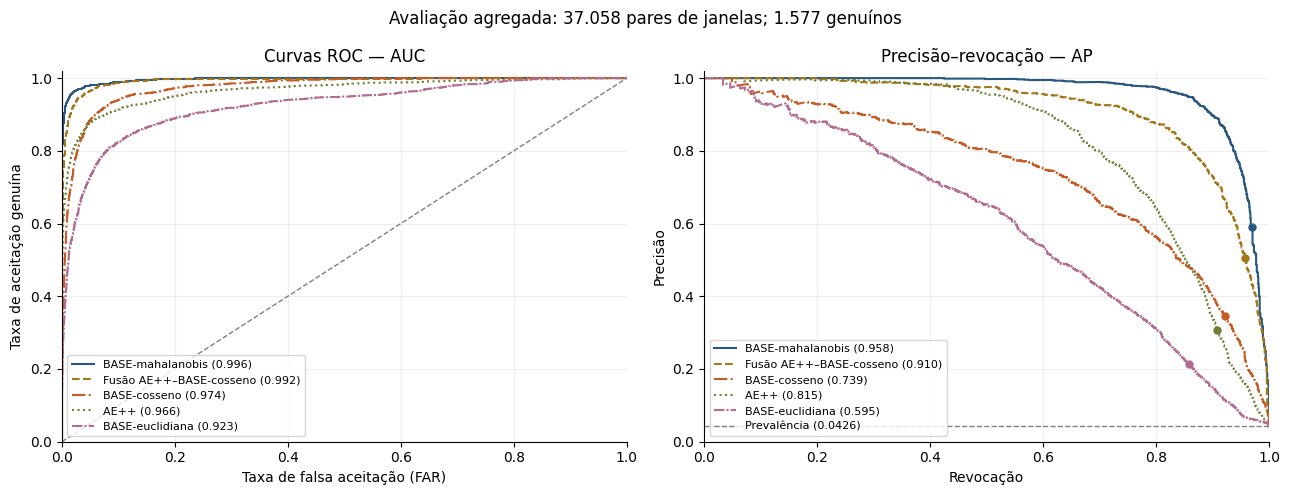

In [15]:
colors=["#285780","#a47718","#c75b25","#717d35","#b46c91"]
styles=["-","--","-.",":",(0,(5,1,1,1))]
fig,axes=plt.subplots(1,2,figsize=(13,5))
for (name,color,style) in zip(metrics["Método"],colors,styles):
    fpr,tpr,recall,precision=curves[name]
    row=metrics.set_index("Método").loc[name]
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f"{name} ({row.AUC:.3f})")
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f"{name} ({row.AP:.3f})")
    axes[1].scatter(row["Revocação"],row["Precisão"],color=color,s=25)
axes[0].plot([0,1],[0,1],color="gray",linestyle="--",linewidth=1)
axes[0].set(title="Curvas ROC — AUC",xlabel="Taxa de falsa aceitação (FAR)",ylabel="Taxa de aceitação genuína")
axes[1].axhline(y_vec.mean(),color="gray",linestyle="--",linewidth=1,label=f"Prevalência ({y_vec.mean():.4f})")
axes[1].set(title="Precisão–revocação — AP",xlabel="Revocação",ylabel="Precisão")
for ax in axes:
    ax.set_xlim(0,1);ax.set_ylim(0,1.02);ax.grid(alpha=0.2);ax.legend(fontsize=8,loc="lower left")
fig.suptitle(f"Avaliação agregada: {len(y_vec):,} pares de janelas; {int(y_vec.sum()):,} genuínos".replace(",", "."))
fig.tight_layout()
save_figure("roc_pr_verificadores")

## 8. Confronto com o Capítulo 5

A tabela seguinte mantém separados os valores publicados e os calculados nesta execução. Como critério de conferência desta revisão, para AUC, EER, acurácia e F1, diferenças de até 0,001 são identificadas como pequenas variações; a igualdade na precisão publicada usa seis casas decimais. Limiares e contagens são apresentados separadamente, pois dependem da escala e do ponto discreto de operação. Nenhum parâmetro é ajustado em função dessa comparação.

In [16]:
published=pd.DataFrame([
    ["BASE-mahalanobis",.995965,.029910,.969993,.733461,-231.059158,1530,47,1065,34416],
    ["Fusão AE++–BASE-cosseno",.991874,.043036,.957040,.654664,.867892,1509,68,1524,33957],
    ["BASE-cosseno",.974369,.077822,.922338,.502592,.289811,1454,123,2755,32726],
    ["AE++",.965691,.091385,.908549,.458193,-.517872,1433,144,3245,32236],
    ["BASE-euclidiana",.922891,.140396,.859949,.343038,-11.768059,1355,222,4968,30513]],
    columns=["Método","AUC","EER","ACC@EER","F1@EER","Limiar","TP","FN","FP","TN"]).set_index("Método")
rows=[]
for _,row in metrics.iterrows():
    for metric in ["AUC","EER","ACC@EER","F1@EER"]:
        target=published.loc[row["Método"],metric]
        difference=float(row[metric]-target)
        status="Compatível com a precisão publicada" if abs(difference)<=.0000005 else ("Pequena variação" if abs(difference)<=.001 else "Divergência")
        rows.append({"Método":row["Método"],"Métrica":metric,"Publicado":target,"Calculado":row[metric],"Diferença":difference,"Situação":status})
comparison=pd.DataFrame(rows)
comparison.to_csv(RESULTS/"comparacao_capitulo5.csv",index=False)
display(comparison)
counts_comparison=metrics.set_index("Método")[["TP","FN","FP","TN","Limiar"]].join(published[["TP","FN","FP","TN","Limiar"]],lsuffix=" calculado",rsuffix=" publicado")
counts_comparison.to_csv(RESULTS/"comparacao_contagens_limiares.csv")
display(counts_comparison)
coverage={"gravacoes":len(idx_df),"sessoes":idx_df.session_group.nunique(),"pares_gravacoes":len(pairs),
          "janelas_pareadas":len(y_vec),"genuinos":int(y_vec.sum()),"impostores":int((y_vec==0).sum()),
          "dimensao_dispositivo":FA.shape[1],"dimensao_pareada":X_pairs.shape[1],
          "particao_independente_por_sessoes":False}
manifest={"versions":VERSIONS,"parameters":EXTRACTION_PARAMETERS,"dataset_sha256":dataset_digest,"extractor_sha256":extractor_digest,
          "coverage":coverage,"aepp_seed":best_pack["seed"],"comparison":comparison.Situação.value_counts().to_dict()}
(RESULTS/"manifesto_execucao.json").write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
display(pd.Series(coverage,name="Verificação").to_frame())
best=metrics.iloc[0]
display(Markdown(f"**Resultado calculado:** {best['Método']}, AUC **{best['AUC']:.6f}**, EER **{100*best['EER']:.3f}%**. "
                 "A execução reproduz o ajuste e a avaliação agregados do código fornecido; a validação independente por sessões permanece pendente."))

,Método,Métrica,Publicado,Calculado,Diferença,Situação
0,BASE-mahalanobis,AUC,0.995965,0.995965,-1.515222e-07,Compatível com a precisão publicada
1,BASE-mahalanobis,EER,0.029910,0.029910,-2.554203e-07,Compatível com a precisão publicada
2,BASE-mahalanobis,ACC@EER,0.969993,0.969993,-1.602893e-08,Compatível com a precisão publicada
3,BASE-mahalanobis,F1@EER,0.733461,0.733461,1.697028e-07,Compatível com a precisão publicada
4,Fusão AE++–BASE-cosseno,AUC,0.991874,0.991863,-1.073316e-05,Pequena variação
5,Fusão AE++–BASE-cosseno,EER,0.043036,0.041810,-1.225774e-03,Divergência
6,Fusão AE++–BASE-cosseno,ACC@EER,0.957040,0.958228,1.187643e-03,Divergência
7,Fusão AE++–BASE-cosseno,F1@EER,0.654664,0.661269,6.605147e-03,Divergência
8,BASE-cosseno,AUC,0.974369,0.974366,-2.750374e-06,Pequena variação
9,BASE-cosseno,EER,0.077822,0.077822,-3.066189e-07,Compatível com a precisão publicada


,TP calculado,FN calculado,FP calculado,TN calculado,Limiar calculado,TP publicado,FN publicado,FP publicado,TN publicado,Limiar publicado
Método,,,,,,,,,,
BASE-mahalanobis,1530,47,1065,34416,-231.043314,1530,47,1065,34416,-231.059158
Fusão AE++–BASE-cosseno,1511,66,1482,33999,0.885038,1509,68,1524,33957,0.867892
BASE-cosseno,1454,123,2755,32726,0.289812,1454,123,2755,32726,0.289811
AE++,1433,144,3230,32251,-0.520045,1433,144,3245,32236,-0.517872
BASE-euclidiana,1355,222,4968,30513,-11.768050,1355,222,4968,30513,-11.768059


,Verificação
gravacoes,112
sessoes,7
pares_gravacoes,1356
janelas_pareadas,37058
genuinos,1577
impostores,35481
dimensao_dispositivo,126
dimensao_pareada,505
particao_independente_por_sessoes,False


**Resultado calculado:** BASE-mahalanobis, AUC **0.995965**, EER **2.991%**. A execução reproduz o ajuste e a avaliação agregados do código fornecido; a validação independente por sessões permanece pendente.